# Classify Deep - Mã thực nghiệm đầy đủ (development only)

Notebook này **trực tiếp huấn luyện** Dummy, LR, LinearSVC, Random Forest, tuning và PCA (768/256/512). Chạy từ trên xuống để tạo lại toàn bộ CSV, OOF, mô hình và hình. Final test được giữ nguyên. Kết quả, bảng/đồ thị hiện bên dưới chỉ xuất hiện sau khi cell thực thi. Các phân tích dài đã được chuyển sang report/overleaf/classify_deep.tex.


## B1. Nạp embedding và tạo 5-fold CV

Chỉ dùng train+val, seed 42; cùng fold cho mọi pipeline; StandardScaler nằm trong fold.

In [1]:
import sys
from pathlib import Path

repo_root = Path.cwd()
if not (repo_root / "modules" / "classify.py").is_file():
    repo_root = repo_root.parent
if not (repo_root / "modules" / "classify.py").is_file():
    raise FileNotFoundError("Hãy chạy notebook từ thư mục gốc hoặc notebooks/.")

sys.path.insert(0, str(repo_root))
from modules.classify import (
    DEEP_FEATURE_DIMS,
    evaluate_deep_cv,
    file_sha256,
    load_deep_embedding,
    load_deep_metadata,
    make_deep_folds,
    save_deep_results,
)

development, label2id, prep, n_rows = load_deep_metadata(repo_root)
seed = prep["seed"]
print(f"Development: {len(development):,}/{n_rows:,} ảnh, {len(label2id)} lớp, seed={seed}")
for name in DEEP_FEATURE_DIMS:
    X = load_deep_embedding(repo_root, name, development, prep, n_rows)
    print(f"{name}: {X.shape}, {X.dtype}")
    del X

development["label"].value_counts().reindex(label2id)

Development: 12,692/15,866 ảnh, 12 lớp, seed=42
resnet50: (12692, 2048), float32
efficientnet_b0: (12692, 1280), float32
vit_b16: (12692, 768), float32
label
battery         783
biological      828
brown-glass     495
cardboard       749
clothes        4228
green-glass     513
metal           669
paper           886
plastic         720
shoes          1605
trash           581
white-glass     635
Name: count, dtype: int64


In [2]:
folds, fold_table = make_deep_folds(development, seed)
for fold_id, (train_idx, val_idx) in enumerate(folds, start=1):
    print(f"Fold {fold_id}: train={len(train_idx):,}, validation={len(val_idx):,}")

fold_path = repo_root / "artifacts" / "results" / "classify_deep" / "folds.csv"
fold_csv = fold_table.to_csv(index=False, lineterminator="\n")
fold_path.parent.mkdir(parents=True, exist_ok=True)
try:
    with fold_path.open("x", encoding="utf-8", newline="") as file:
        file.write(fold_csv)
except FileExistsError:
    if fold_path.read_text(encoding="utf-8") != fold_csv:
        raise ValueError(f"Bảng fold hiện có khác kết quả vừa tạo: {fold_path}")

fold_table["fold_id"].value_counts().sort_index()

Fold 1: train=10,153, validation=2,539
Fold 2: train=10,153, validation=2,539
Fold 3: train=10,154, validation=2,538
Fold 4: train=10,154, validation=2,538
Fold 5: train=10,154, validation=2,538
fold_id
1    2539
2    2539
3    2538
4    2538
5    2538
Name: count, dtype: int64


## B2. Baseline - Dummy và Logistic Regression

Các pipeline được fit thực sự trong từng fold và lưu metric/OOF mới.

In [3]:
import platform
import warnings

import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

y = development["label_id"].to_numpy()
lr_params = {"solver": "lbfgs", "C": 1.0, "max_iter": 1000}
logistic = make_pipeline(StandardScaler(), LogisticRegression(**lr_params))
experiments = [("dummy", "no_embedding", DummyClassifier(strategy="most_frequent"))]
experiments.extend(("logistic_regression", name, logistic) for name in DEEP_FEATURE_DIMS)

fold_scores = []
oof_predictions = []
blas_threads = 4

with threadpool_limits(limits=blas_threads, user_api="blas"), warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    for model_name, embedding, estimator in experiments:
        if embedding == "no_embedding":
            X = np.zeros((len(y), 1), dtype=np.float32)
        else:
            X = load_deep_embedding(repo_root, embedding, development, prep, n_rows)

        scores, predictions = evaluate_deep_cv(estimator, X, y, folds)
        fold_scores.append(scores.assign(model=model_name, embedding=embedding))
        oof_predictions.append(fold_table.assign(
            model=model_name, embedding=embedding, y_true=y, y_pred=predictions
        ))
        print(f"Đã chạy {model_name} / {embedding}")
        del X

baseline_metrics = pd.concat(fold_scores, ignore_index=True)
baseline_oof = pd.concat(oof_predictions, ignore_index=True)

Đã chạy dummy / no_embedding
Đã chạy logistic_regression / resnet50
Đã chạy logistic_regression / efficientnet_b0
Đã chạy logistic_regression / vit_b16


In [4]:
results_dir = fold_path.parent
input_files = [
    repo_root / "data" / "processed" / filename
    for filename in ("meta.csv", "label2id.json", "config.json")
]
input_files.append(fold_path)
input_files.extend(
    repo_root / "artifacts" / "features" / f"{name}{suffix}"
    for name in DEEP_FEATURE_DIMS
    for suffix in (".npy", ".json")
)

run_info = {
    "cv": {"n_splits": len(folds), "shuffle": True, "seed": seed, "std_ddof": 1},
    "dummy": {"strategy": "most_frequent"},
    "logistic_regression": {
        "scaler": "StandardScaler", "regularization": "l2",
        "class_weight": None, **lr_params,
    },
    "label2id": label2id,
    "blas_threads": blas_threads,
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    },
    "input_sha256": {
        path.relative_to(repo_root).as_posix(): file_sha256(path) for path in input_files
    },
}

baseline_summary = save_deep_results(
    results_dir, "baseline", baseline_metrics, baseline_oof, run_info
)
baseline_summary.round(4)

              model       embedding  macro_f1_mean  macro_f1_std  accuracy_mean  accuracy_std  macro_precision_mean  macro_precision_std  macro_recall_mean  macro_recall_std  fit_seconds_mean  fit_seconds_std  predict_seconds_mean  predict_seconds_std
              dummy    no_embedding         0.0416        0.0000         0.3331        0.0002                0.0278               0.0000             0.0833            0.0000            0.0004           0.0001                0.0001               0.0000
logistic_regression        resnet50         0.9272        0.0035         0.9497        0.0022                0.9281               0.0034             0.9269            0.0035            1.6250           0.1219                0.0298               0.0108
logistic_regression efficientnet_b0         0.9401        0.0024         0.9584        0.0019                0.9406               0.0025             0.9402            0.0026            0.7462           0.0538                0.0188              

## B3. Model comparison - 9 tổ hợp

Fit LinearSVC, RF trên ResNet50, EfficientNet-B0, ViT-B/16; ghép với LR ở B2.

In [5]:
import json
from concurrent.futures import ThreadPoolExecutor
import platform
import warnings

import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

results_dir = fold_path.parent
baseline_path = results_dir / "baseline_run.json"
baseline_run = json.loads(baseline_path.read_text(encoding="utf-8"))
cv_config = {"n_splits": len(folds), "shuffle": True, "seed": seed, "std_ddof": 1}
blas_threads = 4
if baseline_run["cv"] != cv_config or baseline_run["label2id"] != label2id:
    raise ValueError("Kết quả Dummy và Logistic Regression dùng cấu hình fold hoặc nhãn khác.")

for filename, digest in baseline_run["input_sha256"].items():
    if file_sha256(repo_root / filename) != digest:
        raise ValueError(f"Đầu vào đã thay đổi từ lần chạy baseline: {filename}")
for filename in ("baseline_cv_metrics.csv", "baseline_oof_predictions.csv"):
    if file_sha256(results_dir / filename) != baseline_run["output_sha256"][filename]:
        raise ValueError(f"File kết quả baseline không khớp checksum: {filename}")

baseline_metrics = pd.read_csv(results_dir / "baseline_cv_metrics.csv")
baseline_oof = pd.read_csv(results_dir / "baseline_oof_predictions.csv", dtype={"md5": str})
y = development["label_id"].to_numpy()
svc_params = {"C": 0.001, "dual": True, "tol": 0.001, "max_iter": 5000, "random_state": seed}
forest_params = {
    "n_estimators": 100, "max_features": "sqrt", "random_state": seed, "n_jobs": 4,
}
models = {
    "linear_svc": make_pipeline(StandardScaler(), LinearSVC(**svc_params)),
    "random_forest": RandomForestClassifier(**forest_params),
}

fold_scores = [baseline_metrics]
oof_predictions = [baseline_oof]
svc_workers = 3


def evaluate_embedding(embedding, model_name, estimator):
    X = load_deep_embedding(repo_root, embedding, development, prep, n_rows)
    print(f"Đang chạy {model_name} / {embedding}", flush=True)
    scores, predictions = evaluate_deep_cv(estimator, X, y, folds)
    print(f"Xong {model_name} / {embedding}: {scores['fit_seconds'].sum():.1f} giây fit", flush=True)
    return (
        scores.assign(model=model_name, embedding=embedding),
        fold_table.assign(model=model_name, embedding=embedding, y_true=y, y_pred=predictions),
    )


with threadpool_limits(limits=blas_threads, user_api="blas"), warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    for model_name, estimator in models.items():
        if model_name == "linear_svc":
            with ThreadPoolExecutor(max_workers=svc_workers) as executor:
                futures = [
                    executor.submit(evaluate_embedding, embedding, model_name, estimator)
                    for embedding in DEEP_FEATURE_DIMS
                ]
                evaluated = [future.result() for future in futures]
        else:
            evaluated = [
                evaluate_embedding(embedding, model_name, estimator)
                for embedding in DEEP_FEATURE_DIMS
            ]
        for scores, predictions in evaluated:
            fold_scores.append(scores)
            oof_predictions.append(predictions)

comparison_metrics = pd.concat(fold_scores, ignore_index=True)
comparison_oof = pd.concat(oof_predictions, ignore_index=True)

Đang chạy linear_svc / vit_b16
Đang chạy linear_svc / efficientnet_b0
Đang chạy linear_svc / resnet50
Xong linear_svc / vit_b16: 27.8 giây fit
Xong linear_svc / efficientnet_b0: 68.4 giây fit
Xong linear_svc / resnet50: 146.7 giây fit
Đang chạy random_forest / resnet50
Xong random_forest / resnet50: 82.0 giây fit
Đang chạy random_forest / efficientnet_b0
Xong random_forest / efficientnet_b0: 53.4 giây fit
Đang chạy random_forest / vit_b16
Xong random_forest / vit_b16: 35.7 giây fit


In [6]:
comparison_run = {
    "cv": cv_config,
    "label2id": label2id,
    "blas_threads": blas_threads,
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    },
    "input_sha256": baseline_run["input_sha256"],
    "baseline_run_sha256": file_sha256(baseline_path),
    "linear_svc": {
        "scaler": "StandardScaler", "loss": "squared_hinge", "penalty": "l2",
        "multi_class": "ovr", "class_weight": None, "embedding_workers": svc_workers, **svc_params,
    },
    "random_forest": {
        "scaler": None, "bootstrap": True, "max_depth": None, "min_samples_leaf": 1,
        "class_weight": None, **forest_params,
    },
}
comparison_summary = save_deep_results(
    results_dir, "comparison", comparison_metrics, comparison_oof, comparison_run
)
comparison_summary.sort_values("macro_f1_mean", ascending=False).round(4)

              model       embedding  macro_f1_mean  macro_f1_std  accuracy_mean  accuracy_std  macro_precision_mean  macro_precision_std  macro_recall_mean  macro_recall_std  fit_seconds_mean  fit_seconds_std  predict_seconds_mean  predict_seconds_std
         linear_svc        resnet50         0.9417        0.0033         0.9593        0.0020                0.9452               0.0040             0.9392            0.0028           29.3468           3.0358                0.0509               0.0053
logistic_regression         vit_b16         0.9411        0.0033         0.9593        0.0020                0.9413               0.0039             0.9413            0.0026            0.5093           0.0718                0.0099               0.0032
         linear_svc         vit_b16         0.9410        0.0060         0.9595        0.0038                0.9423               0.0063             0.9404            0.0054            5.5669           0.2282                0.0242              

## B4. Tuning - outer 5 folds, inner validation

Chọn embedding theo B3; GridSearchCV trên phần train của outer fold rồi đo Macro-F1 của outer val. Không gọi đây là đánh giá final test.

In [7]:
import json
import platform
import warnings

import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

results_dir = fold_path.parent
comparison_path = results_dir / "comparison_run.json"
comparison_run = json.loads(comparison_path.read_text(encoding="utf-8"))
outer_config = {"n_splits": len(folds), "shuffle": True, "seed": seed, "std_ddof": 1}
if comparison_run["cv"] != outer_config or comparison_run["label2id"] != label2id:
    raise ValueError("Kết quả B3 dùng folds hoặc nhãn khác.")
for filename, digest in comparison_run["input_sha256"].items():
    if file_sha256(repo_root / filename) != digest:
        raise ValueError(f"Đầu vào thay đổi từ B3: {filename}")
for filename, digest in comparison_run["output_sha256"].items():
    if file_sha256(results_dir / filename) != digest:
        raise ValueError(f"Kết quả B3 không khớp checksum: {filename}")

experiments = [
    (
        "logistic_regression", "vit_b16",
        make_pipeline(StandardScaler(), LogisticRegression(solver="lbfgs", max_iter=1000)),
        {"logisticregression__C": [0.1, 1.0, 10.0]},
    ),
    (
        "linear_svc", "resnet50",
        make_pipeline(StandardScaler(), LinearSVC(
            dual=True, tol=0.001, max_iter=5000, random_state=seed
        )),
        {"linearsvc__C": [0.0003, 0.001, 0.003]},
    ),
    (
        "random_forest", "resnet50",
        RandomForestClassifier(n_estimators=100, max_features="sqrt", random_state=seed, n_jobs=4),
        {"min_samples_leaf": [1, 2]},
    ),
]
y = development["label_id"].to_numpy()
inner_cv = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
inner_validation = []
for fold_id, (train_idx, _) in enumerate(folds, start=1):
    _, inner_val_idx = next(inner_cv.split(np.zeros(len(train_idx)), y[train_idx]))
    inner_validation.append(pd.DataFrame({
        "fold_id": fold_id,
        "md5": development.iloc[train_idx[inner_val_idx]]["md5"].to_numpy(),
    }))
inner_path = results_dir / "tuning_inner_validation.csv"
pd.concat(inner_validation, ignore_index=True).to_csv(
    inner_path, index=False, lineterminator="\n"
)

tuning_run = {
    "cv": outer_config,
    "inner_cv": {"method": "StratifiedShuffleSplit", "n_splits": 1, "test_size": 0.2, "seed": seed},
    "selection": "One embedding per classifier family selected from B3 mean Macro F1.",
    "label2id": label2id,
    "parameter_grids": {name: grid for name, _, _, grid in experiments},
    "fixed_parameters": {
        "logistic_regression": {
            key: value for key, value in experiments[0][2][-1].get_params().items()
            if key != "C"
        },
        "linear_svc": {
            key: value for key, value in experiments[1][2][-1].get_params().items()
            if key != "C"
        },
        "random_forest": {
            key: value for key, value in experiments[2][2].get_params().items()
            if key != "min_samples_leaf"
        },
    },
    "preprocessing": {
        "logistic_regression": "StandardScaler", "linear_svc": "StandardScaler",
        "random_forest": None,
    },
    "embeddings": {name: embedding for name, embedding, _, _ in experiments},
    "timing": "fit_seconds includes all inner fits and outer refit. refit_seconds measures the outer refit.",
    "blas_threads": 4,
    "grid_n_jobs": 1,
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    },
    "input_sha256": comparison_run["input_sha256"],
    "comparison_run_sha256": file_sha256(comparison_path),
}
print("LR: 20 fits; LinearSVC: 20 fits; Random Forest: 15 fits.")

LR: 20 fits; LinearSVC: 20 fits; Random Forest: 15 fits.


In [8]:
tuning_scores = []
tuning_predictions = []
tuning_history = []

with threadpool_limits(limits=4, user_api="blas"), warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    for model_name, embedding, estimator, parameter_grid in experiments:
        X = load_deep_embedding(repo_root, embedding, development, prep, n_rows)
        search = GridSearchCV(
            estimator, parameter_grid, scoring="f1_macro", cv=inner_cv,
            refit=True, n_jobs=1, error_score="raise",
        )
        print(f"Tuning {model_name} / {embedding}", flush=True)
        scores, predictions, history = evaluate_deep_cv(
            search, X, y, folds, return_search=True
        )
        tuning_scores.append(scores.assign(model=model_name, embedding=embedding))
        tuning_predictions.append(fold_table.assign(
            model=model_name, embedding=embedding, y_true=y, y_pred=predictions
        ))
        tuning_history.append(history.assign(model=model_name, embedding=embedding))
        del X

        # Lưu sau từng họ mô hình để giữ kết quả của phần đã chạy xong.
        tuning_metrics = pd.concat(tuning_scores, ignore_index=True)
        tuning_oof = pd.concat(tuning_predictions, ignore_index=True)
        search_path = results_dir / "tuning_search.csv"
        pd.concat(tuning_history, ignore_index=True).to_csv(
            search_path, index=False, lineterminator="\n"
        )
        tuning_run["completed_models"] = tuning_metrics["model"].unique().tolist()
        tuning_run["complete"] = len(tuning_run["completed_models"]) == len(experiments)
        tuning_run["additional_output_sha256"] = {
            path.name: file_sha256(path) for path in (inner_path, search_path)
        }
        tuning_summary = save_deep_results(
            results_dir, "tuning", tuning_metrics, tuning_oof, tuning_run
        )
        print(f"Đã lưu {model_name}", flush=True)

tuning_summary.round(4)

Tuning logistic_regression / vit_b16
Fold 1: {'logisticregression__C': 0.1}, outer Macro F1=0.94058
Fold 2: {'logisticregression__C': 0.1}, outer Macro F1=0.94394
Fold 3: {'logisticregression__C': 0.1}, outer Macro F1=0.94606
Fold 4: {'logisticregression__C': 0.1}, outer Macro F1=0.94889
Fold 5: {'logisticregression__C': 1.0}, outer Macro F1=0.94031
Đã lưu logistic_regression
Tuning linear_svc / resnet50
Fold 1: {'linearsvc__C': 0.003}, outer Macro F1=0.94440
Fold 2: {'linearsvc__C': 0.003}, outer Macro F1=0.94838
Fold 3: {'linearsvc__C': 0.003}, outer Macro F1=0.94538
Fold 4: {'linearsvc__C': 0.003}, outer Macro F1=0.94695
Fold 5: {'linearsvc__C': 0.003}, outer Macro F1=0.94052
Đã lưu linear_svc
Tuning random_forest / resnet50
Fold 1: {'min_samples_leaf': 1}, outer Macro F1=0.90802
Fold 2: {'min_samples_leaf': 1}, outer Macro F1=0.90898
Fold 3: {'min_samples_leaf': 2}, outer Macro F1=0.90453
Fold 4: {'min_samples_leaf': 2}, outer Macro F1=0.91076
Fold 5: {'min_samples_leaf': 1}, outer

In [9]:
comparison_metrics = pd.read_csv(results_dir / "comparison_cv_metrics.csv")
paired = tuning_metrics.merge(
    comparison_metrics,
    on=["model", "embedding", "fold_id"],
    suffixes=("_tuned", "_baseline"),
    validate="one_to_one",
)
paired["macro_f1_change"] = paired["macro_f1_tuned"] - paired["macro_f1_baseline"]
paired[[
    "model", "embedding", "fold_id", "best_params",
    "macro_f1_baseline", "macro_f1_tuned", "macro_f1_change",
    "fit_seconds_tuned", "refit_seconds",
]]

              model embedding  fold_id                    best_params  macro_f1_baseline  macro_f1_tuned  macro_f1_change  fit_seconds_tuned  refit_seconds
logistic_regression   vit_b16        1 {"logisticregression__C": 0.1}           0.937558        0.940582         0.003025           2.685695       1.033460
logistic_regression   vit_b16        2 {"logisticregression__C": 0.1}           0.943654        0.943937         0.000283           2.649543       0.929435
logistic_regression   vit_b16        3 {"logisticregression__C": 0.1}           0.938474        0.946063         0.007589           2.308186       0.928979
logistic_regression   vit_b16        4 {"logisticregression__C": 0.1}           0.945285        0.948886         0.003602           2.303178       0.857749
logistic_regression   vit_b16        5 {"logisticregression__C": 1.0}           0.940306        0.940306         0.000000           1.749830       0.412422
         linear_svc  resnet50        1        {"linearsvc__C": 0

## B5. Error analysis - Per-class F1, confusion matrix và đối chiếu ảnh

Tính OOF metrics, nhóm nhầm lẫn và so sánh từng ảnh giữa LR+ViT và LinearSVC+ResNet. Phần giải thích diễn giải đầy đủ nằm trong báo cáo.

In [10]:
import json
import platform

import matplotlib
import sklearn

import numpy as np
import pandas as pd

from modules.classify import summarize_deep_oof

results_dir = fold_path.parent
all_predictions = []
analysis_inputs = {}
for stage, prefix in (("baseline", "comparison"), ("tuned", "tuning")):
    manifest_path = results_dir / f"{prefix}_run.json"
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest["label2id"] != label2id:
        raise ValueError("Ánh xạ nhãn của kết quả khác metadata đang dùng.")
    if prefix == "tuning" and not manifest["complete"]:
        raise ValueError("Tuning chưa chạy đủ các mô hình.")
    for name, digest in manifest["input_sha256"].items():
        if file_sha256(repo_root / name) != digest:
            raise ValueError(f"Đầu vào không khớp checksum: {name}")
    for name, digest in manifest["output_sha256"].items():
        if file_sha256(results_dir / name) != digest:
            raise ValueError(f"Kết quả không khớp checksum: {name}")
    prediction_path = results_dir / f"{prefix}_oof_predictions.csv"
    table = pd.read_csv(prediction_path, dtype={"md5": str})
    all_predictions.append(table.assign(stage=stage))
    analysis_inputs[manifest_path.name] = file_sha256(manifest_path)
    analysis_inputs[prediction_path.name] = file_sha256(prediction_path)

predictions = pd.concat(all_predictions, ignore_index=True)
expected = fold_table.assign(y_true=development["label_id"].to_numpy())
for _, rows in predictions.groupby(["stage", "model", "embedding"], sort=False):
    pd.testing.assert_frame_equal(
        rows[["md5", "fold_id", "y_true"]].reset_index(drop=True), expected
    )

per_class, confusions = summarize_deep_oof(predictions, label2id)
per_class_folds, _ = summarize_deep_oof(predictions, label2id, by_fold=True)
tuned_classes = per_class[per_class["stage"].eq("tuned")]
tuned_classes.sort_values(["model", "f1"])[[
    "model", "label", "support", "precision", "recall", "f1", "fp", "fn"
]]

              model       label  support  precision   recall       f1  fp  fn
         linear_svc     plastic      720   0.896652 0.855556 0.875622  71 104
         linear_svc       metal      669   0.872159 0.917788 0.894392  90  55
         linear_svc white-glass      635   0.909238 0.883465 0.896166  56  74
         linear_svc       paper      886   0.937290 0.944695 0.940978  56  49
         linear_svc brown-glass      495   0.952772 0.937374 0.945010  23  31
         linear_svc green-glass      513   0.956349 0.939571 0.947886  22  31
         linear_svc   cardboard      749   0.969822 0.943925 0.956698  22  42
         linear_svc       trash      581   0.977072 0.953528 0.965157  13  27
         linear_svc     battery      783   0.971831 0.969349 0.970588  22  24
         linear_svc  biological      828   0.961222 0.987923 0.974390  33  10
         linear_svc       shoes     1605   0.976514 0.984424 0.980453  38  25
         linear_svc     clothes     4228   0.990832 0.996925 0.9

In [11]:
keys = ["stage", "model", "embedding"]
directions = confusions[confusions["true_id"].ne(confusions["predicted_id"])].copy()
directions["class_a"] = np.minimum(directions["true_id"], directions["predicted_id"])
directions["class_b"] = np.maximum(directions["true_id"], directions["predicted_id"])
forward = directions["true_id"].eq(directions["class_a"])
directions["a_to_b"] = directions["count"].where(forward, 0)
directions["b_to_a"] = directions["count"].where(~forward, 0)
directions["a_to_b_rate"] = directions["row_rate"].where(forward, 0)
directions["b_to_a_rate"] = directions["row_rate"].where(~forward, 0)
pairs = directions.groupby(keys + ["class_a", "class_b"], sort=False).agg(
    total_errors=("count", "sum"),
    a_to_b=("a_to_b", "sum"), b_to_a=("b_to_a", "sum"),
    a_to_b_rate=("a_to_b_rate", "sum"), b_to_a_rate=("b_to_a_rate", "sum"),
).reset_index()
id2label = {value: name for name, value in label2id.items()}
pairs["label_a"] = pairs["class_a"].map(id2label)
pairs["label_b"] = pairs["class_b"].map(id2label)

tuned = predictions[predictions["stage"].eq("tuned")]
lr_rows = tuned[tuned["model"].eq("logistic_regression")]
svc_rows = tuned[tuned["model"].eq("linear_svc")]
matched = lr_rows[["md5", "fold_id", "y_true", "y_pred"]].merge(
    svc_rows[["md5", "fold_id", "y_true", "y_pred"]],
    on=["md5", "fold_id", "y_true"], suffixes=("_lr", "_svc"), validate="one_to_one",
)
lr_correct = matched["y_pred_lr"].eq(matched["y_true"])
svc_correct = matched["y_pred_svc"].eq(matched["y_true"])
matched["outcome"] = np.select(
    [lr_correct & svc_correct, ~lr_correct & svc_correct, lr_correct & ~svc_correct],
    ["both_correct", "svc_corrects_lr", "svc_breaks_lr"], default="both_wrong",
)
matched["label"] = matched["y_true"].map(id2label)

class_keys = ["class_id", "label", "support"]
measurements = ["precision", "recall", "f1", "fp", "fn"]
lr_classes = tuned_classes[tuned_classes["model"].eq("logistic_regression")]
svc_classes = tuned_classes[tuned_classes["model"].eq("linear_svc")]
class_changes = lr_classes[class_keys + measurements].merge(
    svc_classes[class_keys + measurements], on=class_keys, suffixes=("_lr", "_svc"),
    validate="one_to_one",
)
for metric in ("precision", "recall", "f1"):
    class_changes[f"{metric}_change_pp"] = (
        class_changes[f"{metric}_svc"] - class_changes[f"{metric}_lr"]
    ) * 100

display(matched["outcome"].value_counts())
pairs[pairs["stage"].eq("tuned")].sort_values("total_errors", ascending=False).head(9)[[
    "model", "label_a", "label_b", "a_to_b", "b_to_a",
    "a_to_b_rate", "b_to_a_rate",
]]

outcome
both_correct       11917
svc_corrects_lr      290
svc_breaks_lr        284
both_wrong           201
Name: count, dtype: int64
              model   label_a     label_b  a_to_b  b_to_a  a_to_b_rate  b_to_a_rate
      random_forest   plastic white-glass      45      71     0.062500     0.111811
logistic_regression   plastic white-glass      51      43     0.070833     0.067717
      random_forest cardboard       paper      39      30     0.052069     0.033860
         linear_svc   plastic white-glass      36      30     0.050000     0.047244
      random_forest     metal     plastic      24      28     0.035874     0.038889
logistic_regression cardboard       paper      27      23     0.036048     0.025959
logistic_regression     metal     plastic      25      24     0.037369     0.033333
         linear_svc     metal     plastic      17      24     0.025411     0.033333
      random_forest   battery       metal      20      17     0.025543     0.025411


In [12]:
focus = pairs[
    pairs["stage"].eq("tuned") & pairs["model"].eq("logistic_regression")
].sort_values("total_errors", ascending=False).iloc[0]
a, b = focus["class_a"], focus["class_b"]
lr_pair = (
    (matched["y_true"].eq(a) & matched["y_pred_lr"].eq(b))
    | (matched["y_true"].eq(b) & matched["y_pred_lr"].eq(a))
)
svc_pair = (
    (matched["y_true"].eq(a) & matched["y_pred_svc"].eq(b))
    | (matched["y_true"].eq(b) & matched["y_pred_svc"].eq(a))
)
svc_correct = matched["y_pred_svc"].eq(matched["y_true"])
focus_pair_changes = pd.DataFrame({
    "event": [
        "lr_pair_svc_correct", "lr_pair_svc_same_pair",
        "lr_pair_svc_other_error", "svc_pair_new",
    ],
    "count": [
        (lr_pair & svc_correct).sum(), (lr_pair & svc_pair).sum(),
        (lr_pair & ~svc_correct & ~svc_pair).sum(), (~lr_pair & svc_pair).sum(),
    ],
}).assign(label_a=focus["label_a"], label_b=focus["label_b"])
focus_pair_changes

                  event  count label_a     label_b
    lr_pair_svc_correct     55 plastic white-glass
  lr_pair_svc_same_pair     31 plastic white-glass
lr_pair_svc_other_error      8 plastic white-glass
           svc_pair_new     35 plastic white-glass


Figure(1600x750)


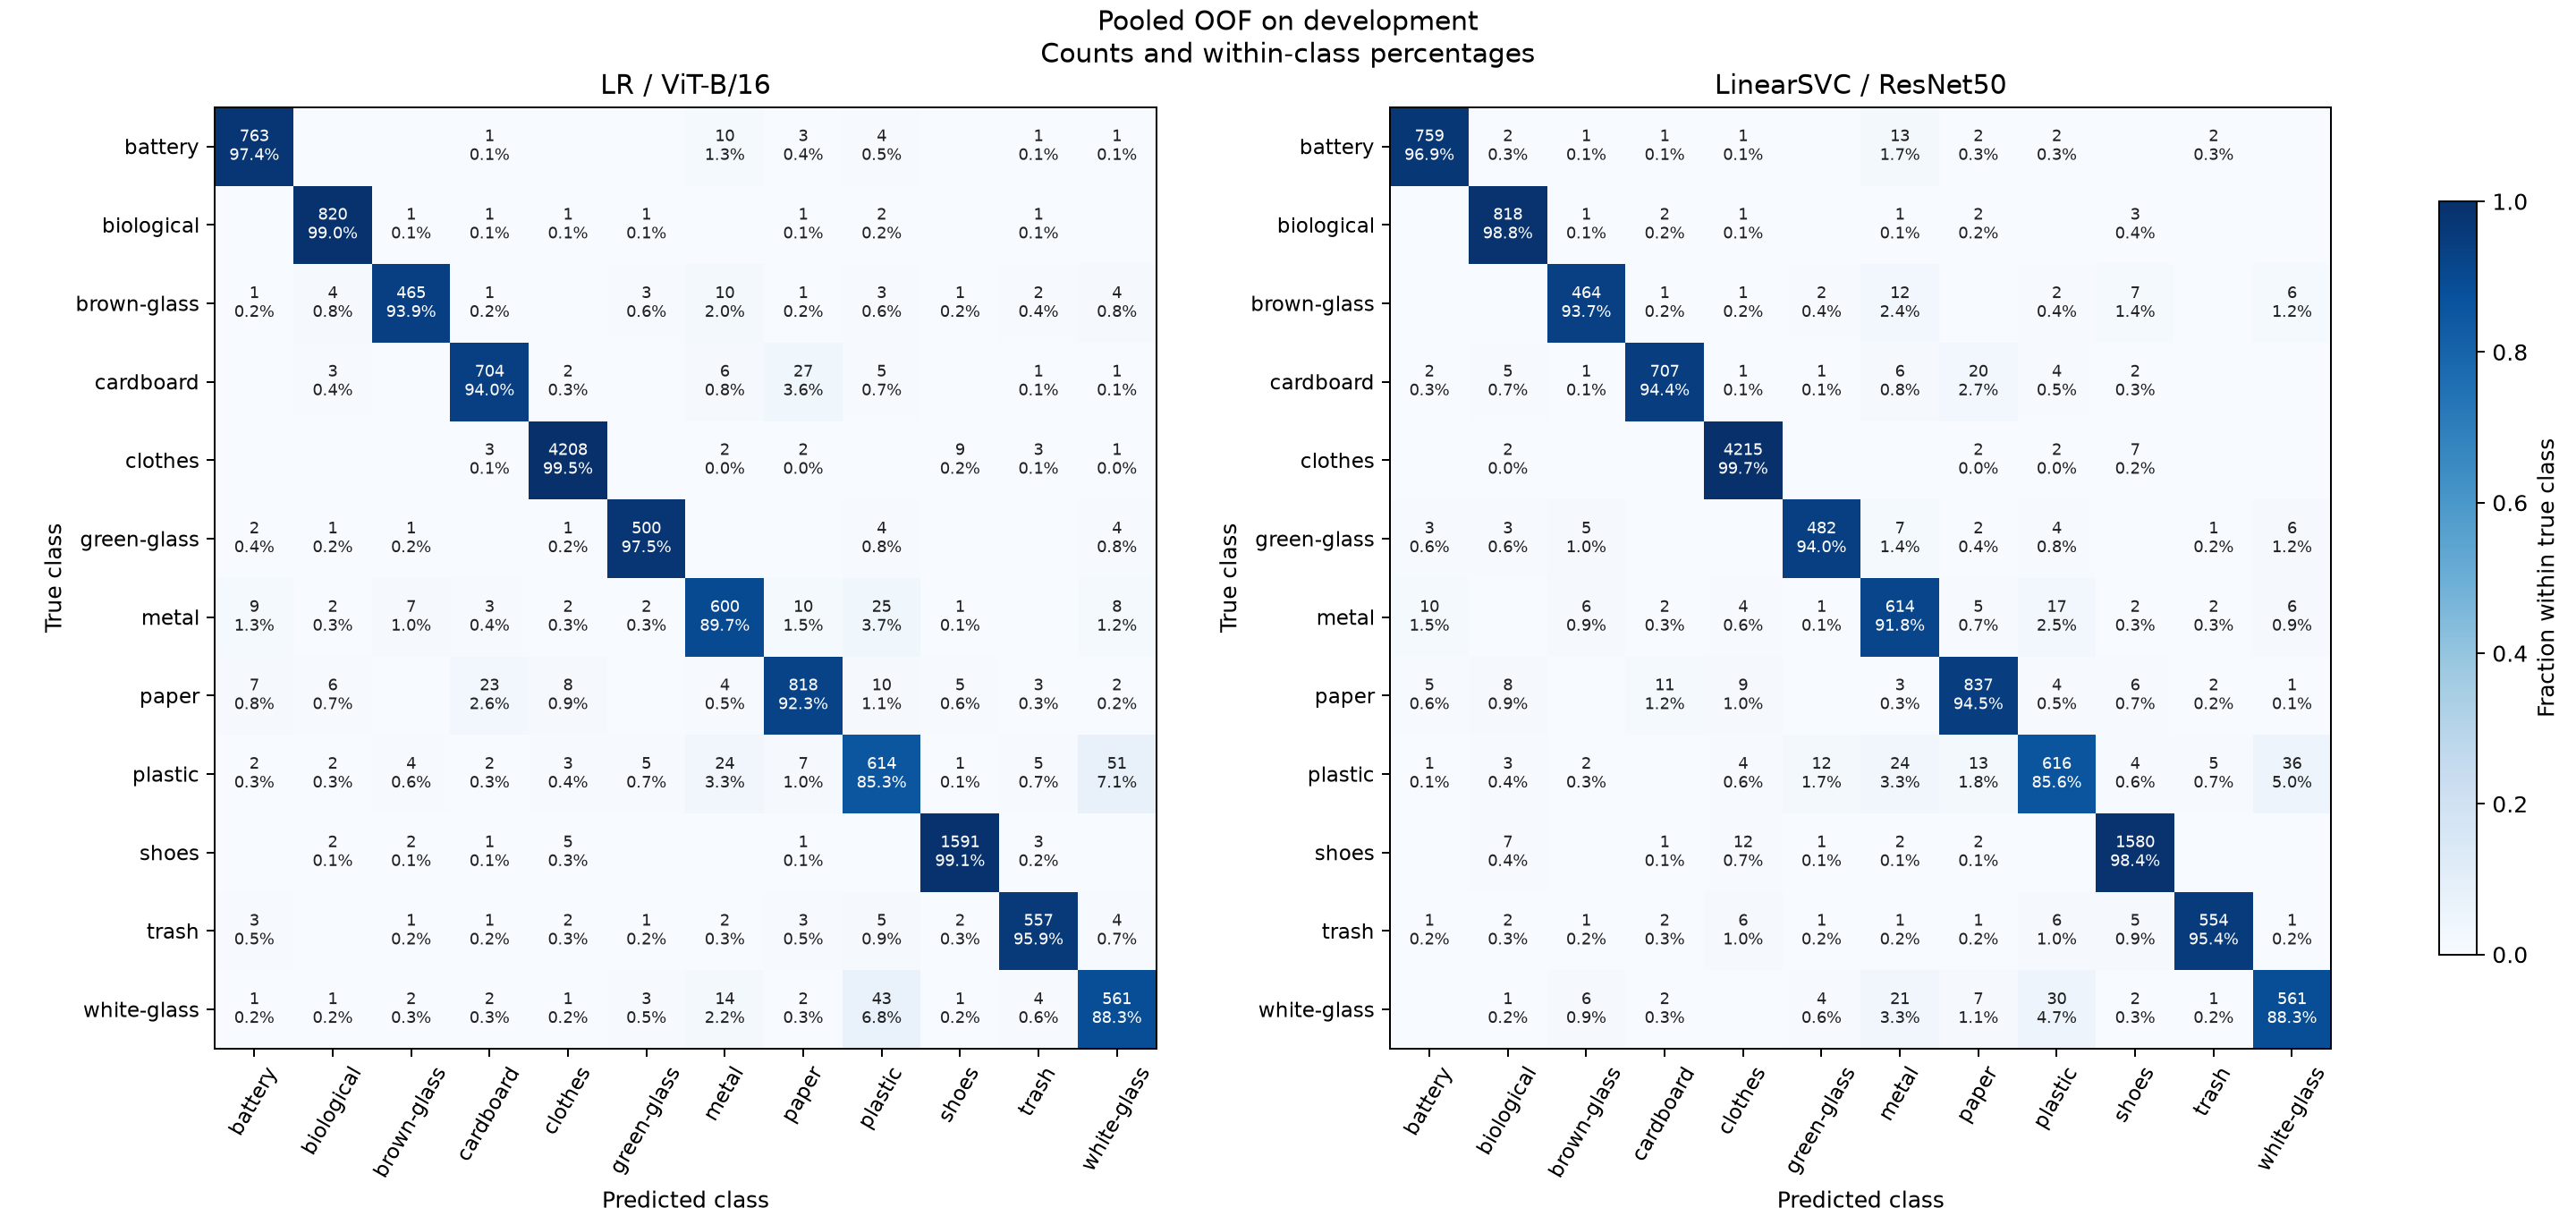

In [13]:
import matplotlib.pyplot as plt

figure_dir = repo_root / "artifacts" / "figures" / "classify_deep"
figure_dir.mkdir(parents=True, exist_ok=True)
class_names = sorted(label2id, key=label2id.get)
configurations = [
    ("logistic_regression", "vit_b16", "LR / ViT-B/16"),
    ("linear_svc", "resnet50", "LinearSVC / ResNet50"),
]
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), layout="constrained")
for ax, (model, embedding, title) in zip(axes, configurations):
    data = confusions[
        confusions["stage"].eq("tuned") & confusions["model"].eq(model)
        & confusions["embedding"].eq(embedding)
    ]
    counts = data.pivot(index="true_label", columns="predicted_label", values="count")
    rates = data.pivot(index="true_label", columns="predicted_label", values="row_rate")
    counts = counts.reindex(index=class_names, columns=class_names).to_numpy()
    rates = rates.reindex(index=class_names, columns=class_names).to_numpy()
    matrix = ax.imshow(rates, vmin=0, vmax=1, cmap="Blues")
    for row, col in np.argwhere(counts > 0):
        ax.text(
            col, row, f"{counts[row, col]}\n{rates[row, col]:.1%}",
            ha="center", va="center", fontsize=7,
            color="white" if rates[row, col] > 0.5 else "#202020",
        )
    ax.set(
        title=title, xlabel="Predicted class", ylabel="True class",
        xticks=range(len(class_names)), yticks=range(len(class_names)),
        xticklabels=class_names, yticklabels=class_names,
    )
    ax.tick_params(axis="x", labelrotation=60, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
fig.colorbar(matrix, ax=axes, shrink=0.8, label="Fraction within true class")
fig.suptitle("Pooled OOF on development\nCounts and within-class percentages")
confusion_figure = figure_dir / "oof_confusion_lr_svc.png"
fig.savefig(confusion_figure, dpi=180)
plt.close(fig)
fig

In [14]:
analysis_tables = {
    "error_analysis_per_class.csv": per_class,
    "error_analysis_per_class_folds.csv": per_class_folds,
    "error_analysis_confusion.csv": confusions,
    "error_analysis_pairs.csv": pairs,
    "error_analysis_paired_predictions.csv": matched,
    "error_analysis_class_changes.csv": class_changes,
    "error_analysis_focus_pair.csv": focus_pair_changes,
}
for filename, table in analysis_tables.items():
    table.to_csv(results_dir / filename, index=False, lineterminator="\n")
analysis_run = {
    "data": "Pooled development OOF predictions, plus separate per-fold class metrics.",
    "label2id": label2id,
    "n_development": len(development),
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "input_sha256": analysis_inputs,
    "focused_comparison": {
        "lr": {"stage": "tuned", "model": "logistic_regression", "embedding": "vit_b16"},
        "svc": {"stage": "tuned", "model": "linear_svc", "embedding": "resnet50"},
    },
    "output_sha256": {
        name: file_sha256(results_dir / name) for name in analysis_tables
    },
    "figure_sha256": {
        path.name: file_sha256(path) for path in (confusion_figure,)
    },
}
(results_dir / "error_analysis_run.json").write_text(
    json.dumps(analysis_run, indent=2) + "\n", encoding="utf-8"
)
class_changes[[
    "label", "precision_lr", "precision_svc", "recall_lr", "recall_svc",
    "fp_lr", "fp_svc", "fn_lr", "fn_svc",
]].round(4)

      label  precision_lr  precision_svc  recall_lr  recall_svc  fp_lr  fp_svc  fn_lr  fn_svc
    battery        0.9683         0.9718     0.9745      0.9693     25      22     20      24
 biological        0.9750         0.9612     0.9903      0.9879     21      33      8      10
brown-glass        0.9627         0.9528     0.9394      0.9374     18      23     30      31
  cardboard        0.9488         0.9698     0.9399      0.9439     38      22     45      42
    clothes        0.9941         0.9908     0.9953      0.9969     25      39     20      13
green-glass        0.9709         0.9563     0.9747      0.9396     15      22     13      31
      metal        0.8929         0.8722     0.8969      0.9178     72      90     69      55
      paper        0.9349         0.9373     0.9233      0.9447     57      56     68      49
    plastic        0.8587         0.8967     0.8528      0.8556    101      71    106     104
      shoes        0.9876         0.9765     0.9913      0.9

## B6. PCA ablation - 768, 512, 256 chiều

Fit ba pipeline với LR C=1, cùng 5 fold; scaler/PCA chỉ fit trong training fold. PCA512 dùng đúng giao thức của experiment 768/256 và lưu bảng pca512_* riêng.

In [15]:
import json
import platform
import warnings

import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

from modules.classify import summarize_deep_oof

results_dir = fold_path.parent
baseline_path = results_dir / "baseline_run.json"
baseline_run = json.loads(baseline_path.read_text(encoding="utf-8"))
outer_config = {"n_splits": len(folds), "shuffle": True, "seed": seed, "std_ddof": 1}
if baseline_run["cv"] != outer_config or baseline_run["label2id"] != label2id:
    raise ValueError("Baseline B2 dùng folds hoặc ánh xạ nhãn khác.")
for name, digest in baseline_run["input_sha256"].items():
    if file_sha256(repo_root / name) != digest:
        raise ValueError(f"Đầu vào thay đổi từ baseline: {name}")
for name, digest in baseline_run["output_sha256"].items():
    if file_sha256(results_dir / name) != digest:
        raise ValueError(f"Kết quả baseline không khớp checksum: {name}")

base_params = {
    key: baseline_run["logistic_regression"][key] for key in ("solver", "C", "max_iter")
}
pca_params = {
    "n_components": 256, "svd_solver": "randomized", "random_state": seed, "whiten": False,
}
models = {
    "logistic_regression": make_pipeline(
        StandardScaler(), LogisticRegression(**base_params)
    ),
    "logistic_regression_pca256": make_pipeline(
        StandardScaler(), PCA(**pca_params), LogisticRegression(**base_params)
    ),
}
X = load_deep_embedding(repo_root, "vit_b16", development, prep, n_rows)
y = development["label_id"].to_numpy()
focus_classes = ["plastic", "white-glass", "metal", "green-glass"]

In [16]:
scores_by_model = []
predictions_by_model = []

with threadpool_limits(limits=4, user_api="blas"), warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    for name, estimator in models.items():
        print(f"PCA ablation {name}", flush=True)
        pca_step = "pca" if name == "logistic_regression_pca256" else None
        scores, predictions = evaluate_deep_cv(
            estimator, X, y, folds, pca_step=pca_step
        )
        scores_by_model.append(scores.assign(model=name, embedding="vit_b16"))
        predictions_by_model.append(fold_table.assign(
            model=name, embedding="vit_b16", y_true=y, y_pred=predictions,
            stage="pca_ablation",
        ))
        print(f"Đã chạy {name}", flush=True)

pca_metrics = pd.concat(scores_by_model, ignore_index=True)
pca_oof = pd.concat(predictions_by_model, ignore_index=True)
baseline_oof = pd.read_csv(results_dir / "baseline_oof_predictions.csv", dtype={"md5": str})
original = baseline_oof[
    baseline_oof["model"].eq("logistic_regression") & baseline_oof["embedding"].eq("vit_b16")
]
repeated = pca_oof[pca_oof["model"].eq("logistic_regression")]
pd.testing.assert_frame_equal(
    repeated[["md5", "fold_id", "y_true", "y_pred"]].reset_index(drop=True),
    original[["md5", "fold_id", "y_true", "y_pred"]].reset_index(drop=True),
)

pca_run = {
    "cv": outer_config, "embedding": "vit_b16",
    "logistic_regression": base_params, "class_weight": None,
    "preprocessing": "StandardScaler before optional PCA, fitted inside each training fold.",
    "pca": pca_params, "focus_classes": focus_classes,
    "blas_threads": 4,
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    },
    "input_sha256": baseline_run["input_sha256"],
    "baseline_run_sha256": file_sha256(baseline_path),
    "analysis_run_sha256": file_sha256(results_dir / "error_analysis_run.json"),
    "timing": "Each fit and predict duration includes the complete pipeline.",
}
pca_summary = save_deep_results(
    results_dir, "pca", pca_metrics, pca_oof, pca_run
)
pca_summary.round(4)

PCA ablation logistic_regression
Đã chạy logistic_regression
PCA ablation logistic_regression_pca256
Đã chạy logistic_regression_pca256
                     model embedding  macro_f1_mean  macro_f1_std  accuracy_mean  accuracy_std  macro_precision_mean  macro_precision_std  macro_recall_mean  macro_recall_std  fit_seconds_mean  fit_seconds_std  predict_seconds_mean  predict_seconds_std
       logistic_regression   vit_b16         0.9411        0.0033         0.9593        0.0020                0.9413               0.0039             0.9413            0.0026            0.5736           0.0769                 0.011               0.0026
logistic_regression_pca256   vit_b16         0.9213        0.0025         0.9463        0.0021                0.9219               0.0023             0.9215            0.0038            1.4724           0.0802                 0.019               0.0028


In [17]:
pca_classes, pca_confusions = summarize_deep_oof(pca_oof, label2id)
pca_class_folds, _ = summarize_deep_oof(pca_oof, label2id, by_fold=True)
class_keys = ["class_id", "label", "support"]
measurements = ["precision", "recall", "f1", "fp", "fn"]
raw_classes = pca_classes[pca_classes["model"].eq("logistic_regression")]
compressed_classes = pca_classes[pca_classes["model"].eq("logistic_regression_pca256")]
pca_changes = raw_classes[class_keys + measurements].merge(
    compressed_classes[class_keys + measurements],
    on=class_keys, suffixes=("_raw", "_pca"), validate="one_to_one",
)
for metric in ("precision", "recall", "f1"):
    pca_changes[f"{metric}_change_pp"] = (
        pca_changes[f"{metric}_pca"] - pca_changes[f"{metric}_raw"]
    ) * 100

compressed_metrics = pca_metrics[pca_metrics["model"].eq("logistic_regression_pca256")]
resources = pd.DataFrame({
    "model": ["logistic_regression", "logistic_regression_pca256"],
    "classifier_dimension": [768, 256],
    "vector_storage_dtype": ["float32", "float32"],
    "vector_payload_bytes": [768 * 4, 256 * 4],
    "pca_components_bytes": [0, int(compressed_metrics["pca_components_bytes"].iloc[0])],
    "retained_variance_mean": [None, compressed_metrics["pca_variance_retained"].mean()],
    "retained_variance_std": [None, compressed_metrics["pca_variance_retained"].std(ddof=1)],
})
pca_tables = {
    "pca_class_metrics.csv": pca_classes,
    "pca_class_metrics_folds.csv": pca_class_folds,
    "pca_confusion.csv": pca_confusions,
    "pca_class_changes.csv": pca_changes,
    "pca_resources.csv": resources,
}
for filename, table in pca_tables.items():
    table.to_csv(results_dir / filename, index=False, lineterminator="\n")
display(resources)
pca_changes[pca_changes["label"].isin(focus_classes)].round(4)

                     model  classifier_dimension vector_storage_dtype  vector_payload_bytes  pca_components_bytes  retained_variance_mean  retained_variance_std
       logistic_regression                   768              float32                  3072                     0                     NaN                    NaN
logistic_regression_pca256                   256              float32                  1024                786432                0.837287               0.000245
 class_id       label  support  precision_raw  recall_raw  f1_raw  fp_raw  fn_raw  precision_pca  recall_pca  f1_pca  fp_pca  fn_pca  precision_change_pp  recall_change_pp  f1_change_pp
        5 green-glass      513         0.9689      0.9727  0.9708      16      14         0.9437      0.9474  0.9455      29      27              -2.5243           -2.5341       -2.5292
        6       metal      669         0.8917      0.8864  0.8891      72      76         0.8554      0.8490  0.8522      96     101             

Figure(1200x600)


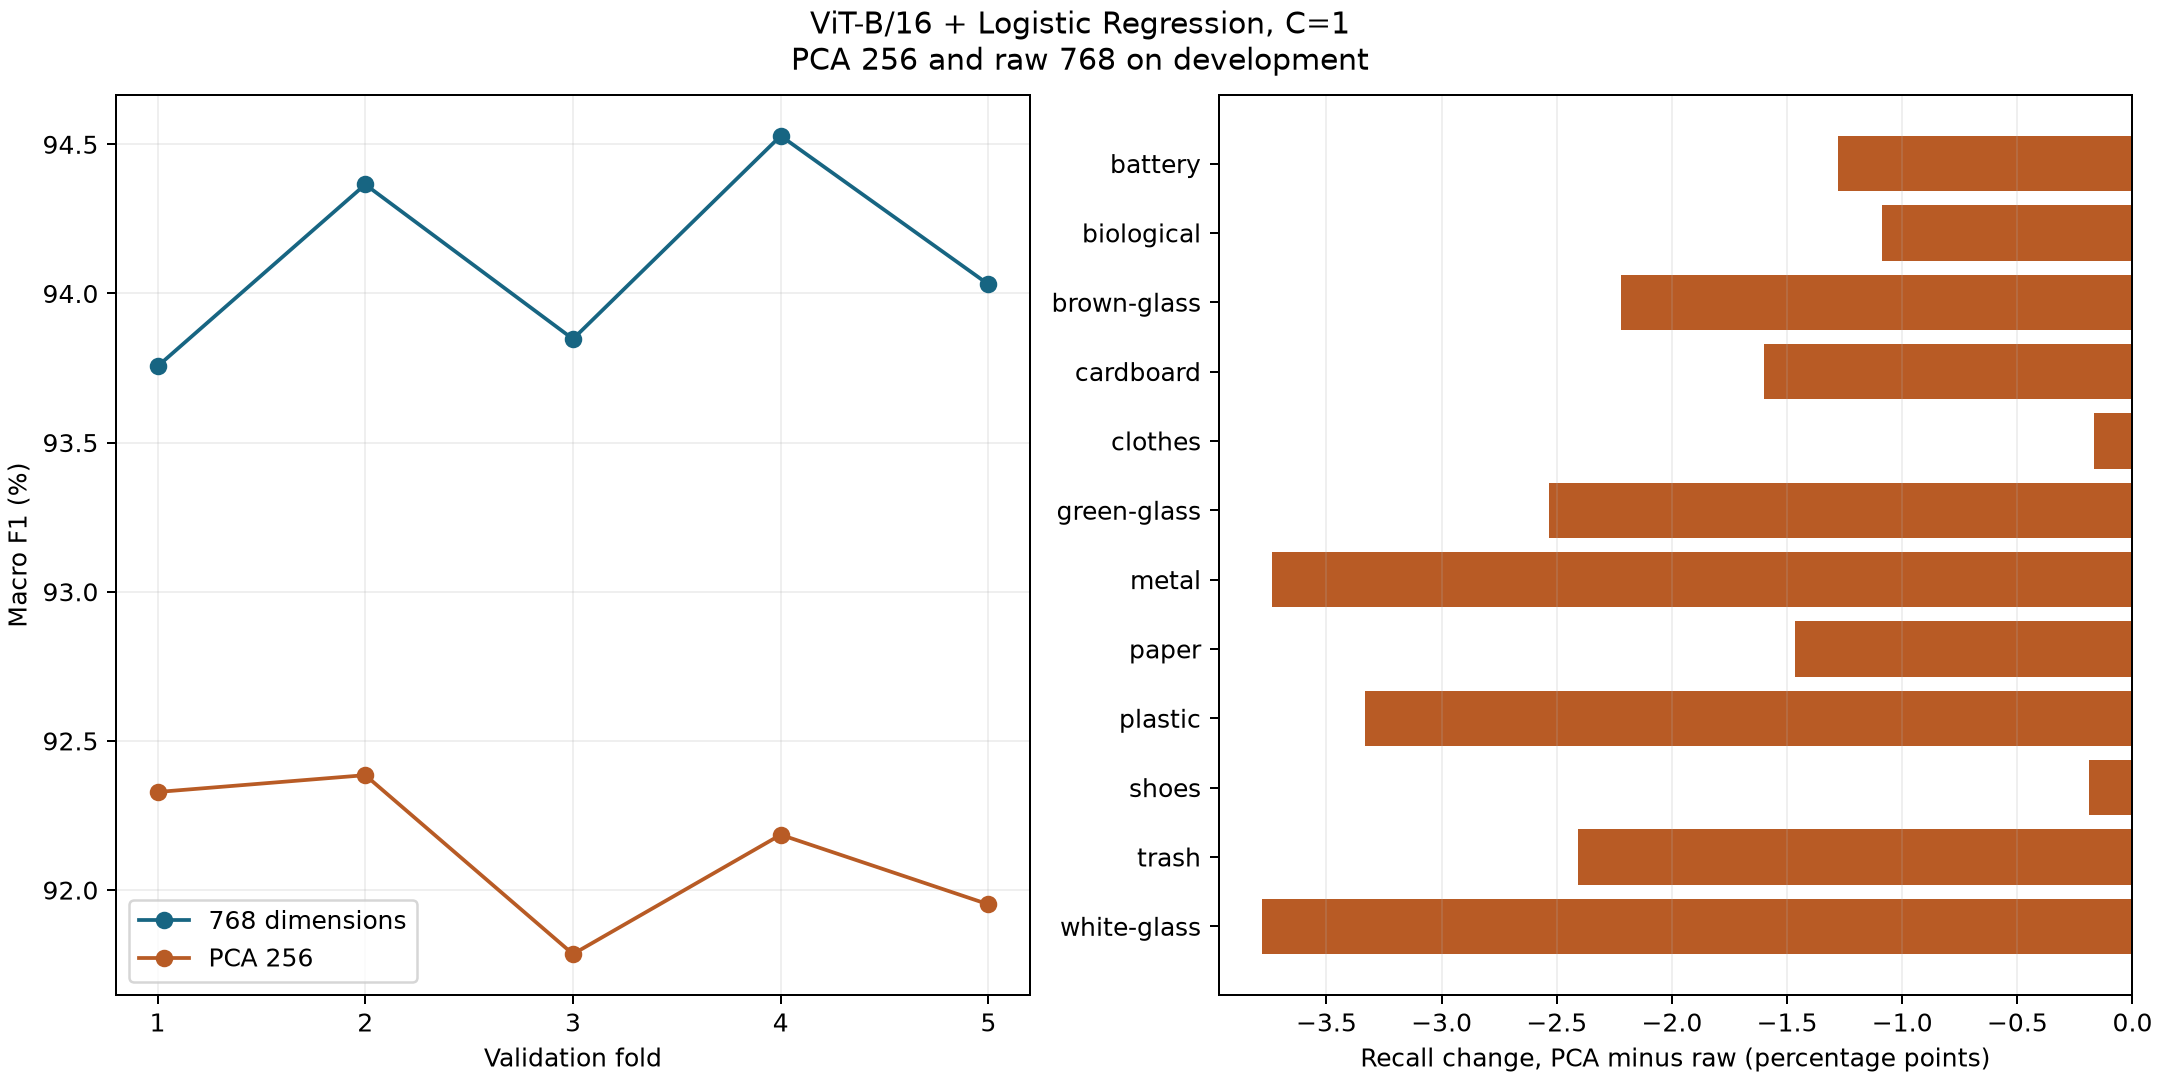

In [18]:
import matplotlib.pyplot as plt

figure_dir = repo_root / "artifacts" / "figures" / "classify_deep"
figure_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
for name, label, color in (
    ("logistic_regression", "768 dimensions", "#176582"),
    ("logistic_regression_pca256", "PCA 256", "#b85b25"),
):
    values = pca_metrics[pca_metrics["model"].eq(name)].sort_values("fold_id")
    axes[0].plot(
        values["fold_id"], values["macro_f1"] * 100,
        marker="o", color=color, label=label,
    )
axes[0].set(xlabel="Validation fold", ylabel="Macro F1 (%)", xticks=range(1, 6))
axes[0].grid(alpha=0.2)
axes[0].legend()
class_names = sorted(label2id, key=label2id.get)
recall_changes = pca_changes.set_index("label").reindex(class_names)["recall_change_pp"]
axes[1].barh(
    class_names, recall_changes,
    color=["#b85b25" if value < 0 else "#176582" for value in recall_changes],
)
axes[1].axvline(0, color="#777777", linewidth=1)
axes[1].invert_yaxis()
axes[1].set(xlabel="Recall change, PCA minus raw (percentage points)")
axes[1].grid(axis="x", alpha=0.2)
fig.suptitle("ViT-B/16 + Logistic Regression, C=1\nPCA 256 and raw 768 on development")
pca_figure = figure_dir / "pca_ablation_folds_recall.png"
fig.savefig(pca_figure, dpi=180)
plt.close(fig)

pca_run["additional_output_sha256"] = {
    filename: file_sha256(results_dir / filename) for filename in pca_tables
}
pca_run["figure_sha256"] = {pca_figure.name: file_sha256(pca_figure)}
pca_summary = save_deep_results(
    results_dir, "pca", pca_metrics, pca_oof, pca_run
)
fig

Starting PCA 512 / LR(C=1): five independent training folds...
                     model embedding  macro_f1_mean  macro_f1_std  accuracy_mean  accuracy_std  macro_precision_mean  macro_precision_std  macro_recall_mean  macro_recall_std  fit_seconds_mean  fit_seconds_std  predict_seconds_mean  predict_seconds_std
logistic_regression_pca512   vit_b16       0.938919      0.003939       0.958163       0.00235               0.93945             0.004569           0.938952          0.003171          1.935103         0.112505               0.02961             0.007754
                     model  classifier_dimension vector_storage_dtype  vector_payload_bytes  pca_components_bytes  retained_variance_mean  retained_variance_std
logistic_regression_pca512                   512              float32                  2048               1572864                0.958318               0.000094
Result verification: same 5 folds, no test rows, own artifacts saved.
                     model  macro_f1_me

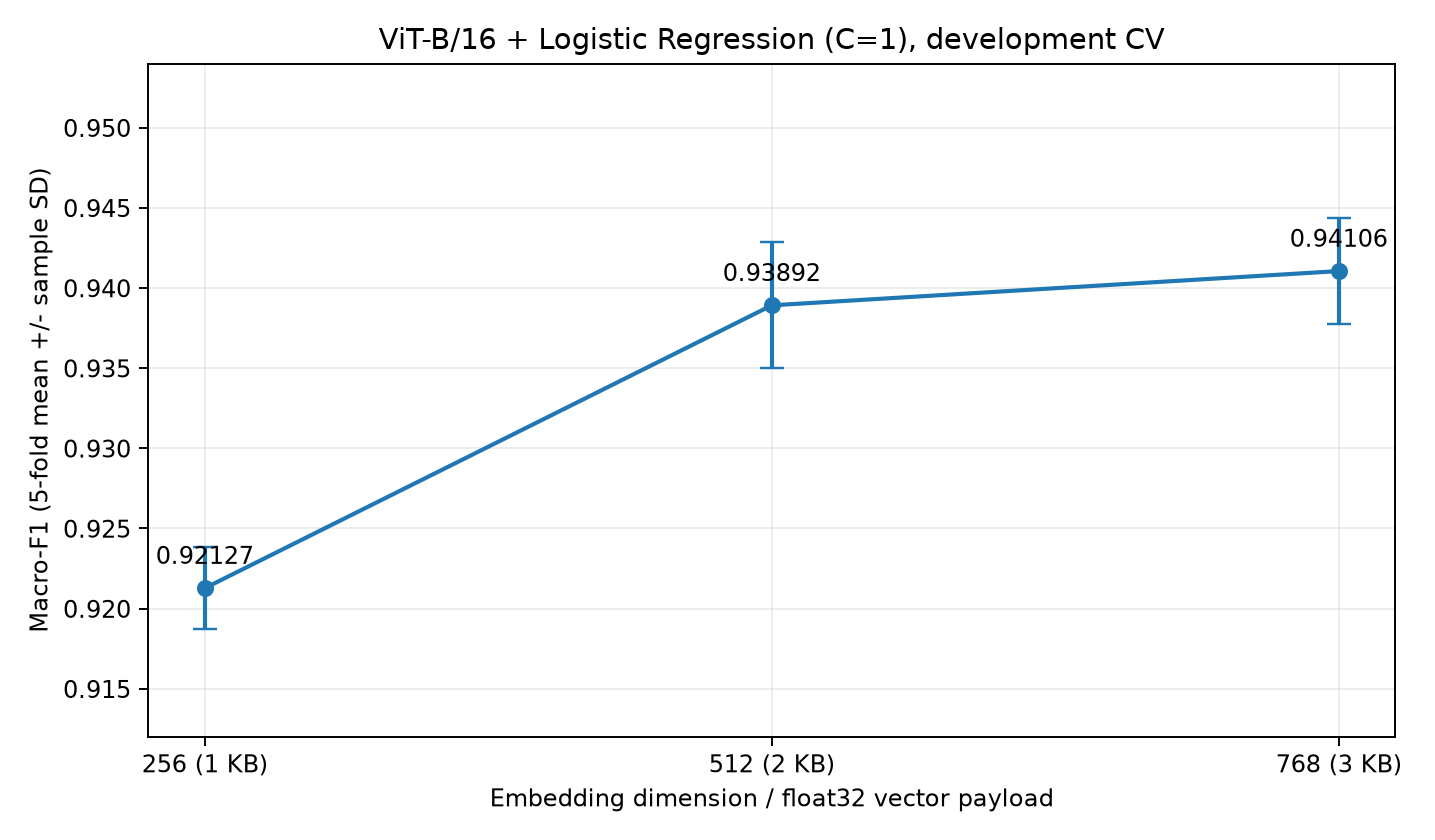

In [19]:
from scripts.pca_512_ablation import main as run_pca512
run_pca512()
pd.concat([pd.read_csv(results_dir / "pca_cv_summary.csv"),pd.read_csv(results_dir / "pca512_cv_summary.csv")],ignore_index=True)[["model","macro_f1_mean","macro_f1_std","accuracy_mean","fit_seconds_mean"]]

## B7. Handoff - fit và lưu mô hình trên toàn development

Tạo pipeline ứng viên trên toàn bộ 12.692 ảnh, lưu joblib cùng metadata và xác minh nạp lại. Không huấn luyện hay chấm final test.

In [20]:
import json
import pandas as pd

results_dir = fold_path.parent
summaries = []
for prefix, design, fit_scope in (
    ("comparison", "fixed_configuration_cv", "fixed pipeline fit"),
    ("tuning", "outer_cv_with_inner_holdout_selection", "inner search plus outer refit"),
    ("pca", "fixed_configuration_pca_ablation", "complete pipeline fit including optional PCA"),
    ("pca512", "fixed_configuration_pca_ablation", "complete pipeline fit including PCA 512"),
):
    run = json.loads((results_dir / f"{prefix}_run.json").read_text(encoding="utf-8"))
    for filename, digest in run["output_sha256"].items():
        if file_sha256(results_dir / filename) != digest:
            raise ValueError(f"Kết quả không khớp checksum: {filename}")
    table = pd.read_csv(results_dir / f"{prefix}_cv_summary.csv")
    summaries.append(table.assign(experiment=prefix, evaluation_design=design, fit_time_scope=fit_scope))

handoff_summary = pd.concat(summaries, ignore_index=True)
handoff_summary.to_csv(
    results_dir / "handoff_cv_summary.csv", index=False, lineterminator="\n"
)
handoff_summary[[
    "experiment", "model", "embedding", "macro_f1_mean", "macro_f1_std",
    "accuracy_mean", "macro_precision_mean", "macro_recall_mean",
]]

experiment                      model       embedding  macro_f1_mean  macro_f1_std  accuracy_mean  macro_precision_mean  macro_recall_mean
comparison                      dummy    no_embedding       0.041647      0.000017       0.333123              0.027760           0.083333
comparison        logistic_regression        resnet50       0.927150      0.003453       0.949732              0.928086           0.926927
comparison        logistic_regression efficientnet_b0       0.940123      0.002404       0.958399              0.940615           0.940221
comparison        logistic_regression         vit_b16       0.941055      0.003320       0.959266              0.941347           0.941287
comparison                 linear_svc        resnet50       0.941729      0.003253       0.959266              0.945158           0.939218
comparison                 linear_svc efficientnet_b0       0.938453      0.006396       0.956744              0.940566           0.936939
comparison                 

In [21]:
import platform
import warnings
from time import perf_counter

import joblib
import numpy as np
import scipy
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

baseline_run = json.loads((results_dir / "baseline_run.json").read_text(encoding="utf-8"))
tuning_run = json.loads((results_dir / "tuning_run.json").read_text(encoding="utf-8"))
for filename, digest in baseline_run["input_sha256"].items():
    if file_sha256(repo_root / filename) != digest:
        raise ValueError(f"Đầu vào thay đổi: {filename}")

lr_params = {
    key: baseline_run["logistic_regression"][key] for key in ("solver", "max_iter")
}
inner_cv = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
lr_search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(**lr_params)),
    tuning_run["parameter_grids"]["logistic_regression"],
    scoring="f1_macro", cv=inner_cv, refit=True, n_jobs=1, error_score="raise",
)
selected_svc = pd.read_csv(results_dir / "tuning_cv_metrics.csv")
selected_svc = selected_svc[selected_svc["model"].eq("linear_svc")]
svc_values = {json.loads(params)["linearsvc__C"] for params in selected_svc["best_params"]}
if len(svc_values) != 1:
    raise ValueError("C của LinearSVC giữa các fold đã thay đổi, cần chốt lại cấu hình bàn giao.")
svc_params = {
    **tuning_run["fixed_parameters"]["linear_svc"], "C": next(iter(svc_values))
}
candidates = [
    ("lr_vit_b16", "vit_b16", lr_search),
    ("linear_svc_resnet50", "resnet50",
     make_pipeline(StandardScaler(), LinearSVC(**svc_params))),
]
model_dir = results_dir / "handoff_models"
model_dir.mkdir(parents=True, exist_ok=True)
candidate_records = {}
y = development["label_id"].to_numpy()

with threadpool_limits(limits=4, user_api="blas"), warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    for candidate_id, embedding, estimator in candidates:
        X = load_deep_embedding(repo_root, embedding, development, prep, n_rows)
        print(f"Fit bàn giao {candidate_id} trên {len(y):,} ảnh development", flush=True)
        start = perf_counter()
        estimator.fit(X, y)
        fit_seconds = perf_counter() - start
        fitted = estimator.best_estimator_ if candidate_id == "lr_vit_b16" else estimator
        if candidate_id == "lr_vit_b16":
            pd.DataFrame({
                "params": [json.dumps(p, sort_keys=True) for p in estimator.cv_results_["params"]],
                "inner_validation_macro_f1": estimator.cv_results_["mean_test_score"],
                "selected": np.arange(len(estimator.cv_results_["params"])) == estimator.best_index_,
            }).to_csv(results_dir / "handoff_lr_selection.csv", index=False, lineterminator="\n")
            _, validation_idx = next(inner_cv.split(X, y))
            development.iloc[validation_idx][["md5"]].to_csv(
                results_dir / "handoff_lr_validation.csv", index=False, lineterminator="\n"
            )
        model_path = model_dir / f"{candidate_id}.joblib"
        joblib.dump(fitted, model_path, compress=3)
        loaded = joblib.load(model_path)
        np.testing.assert_array_equal(loaded.predict(X[:16]), fitted.predict(X[:16]))
        assert loaded[0].n_samples_seen_ == len(development)
        assert set(loaded.classes_) == set(label2id.values())
        candidate_records[candidate_id] = {
            "embedding": embedding, "input_dimension": int(X.shape[1]),
            "path": model_path.relative_to(repo_root).as_posix(),
            "sha256": file_sha256(model_path),
            "classifier": type(loaded[-1]).__name__,
            "classifier_params": loaded[-1].get_params(),
            "preprocessing": "StandardScaler",
            "trained_on": "development (train + val)",
            "n_training_rows": len(development),
            "fit_seconds": fit_seconds,
        }
        print(f"Đã lưu và kiểm tra nạp lại {candidate_id}", flush=True)
        del X

handoff = {
    "status": "development_candidates",
    "label2id": label2id,
    "development_rows": len(development),
    "cv": tuning_run["cv"],
    "input_sha256": baseline_run["input_sha256"],
    "candidates": candidate_records,
    "lr_selection": {"method": "StratifiedShuffleSplit", "validation_size": 0.2, "seed": seed},
    "cv_evidence": "tuning_cv_summary.csv reports the outer-fold tuning procedure.",
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
        "scipy": scipy.__version__, "joblib": joblib.__version__,
    },
    "source_sha256": {
        name: file_sha256(repo_root / name)
        for name in ("modules/classify.py", "scripts/pca_512_ablation.py")
    },
    "pca512_run_sha256": file_sha256(results_dir / "pca512_run.json"),
    "output_sha256": {
        name: file_sha256(results_dir / name)
        for name in ("handoff_cv_summary.csv", "handoff_lr_selection.csv", "handoff_lr_validation.csv")
    },
}
(results_dir / "handoff.json").write_text(
    json.dumps(handoff, indent=2) + "\n", encoding="utf-8"
)
pd.DataFrame(candidate_records).T.assign(
    C=[record["classifier_params"]["C"] for record in candidate_records.values()]
)[["embedding", "input_dimension", "n_training_rows", "classifier", "C"]]

Fit bàn giao lr_vit_b16 trên 12,692 ảnh development
Đã lưu và kiểm tra nạp lại lr_vit_b16
Fit bàn giao linear_svc_resnet50 trên 12,692 ảnh development
Đã lưu và kiểm tra nạp lại linear_svc_resnet50
embedding input_dimension n_training_rows         classifier     C
  vit_b16             768           12692 LogisticRegression 0.100
 resnet50            2048           12692          LinearSVC 0.003


### Đóng gói và đối chiếu

Các CSV được sinh trực tiếp trong quá trình huấn luyện. Tập hợp kết quả bàn giao với script bổ sung, ảnh và manifest; lưu notebook có output sau khi chạy.

In [22]:
from pathlib import Path
print("Artifacts:", results_dir)
print("PCA 512:", (results_dir/"pca512_cv_summary.csv").exists())
print("Handoff candidates:", list(json.loads((results_dir/"handoff.json").read_text(encoding="utf-8"))["candidates"]))

Artifacts: C:\Users\Admin\Documents\GarbageClassification\artifacts\results\classify_deep
PCA 512: True
Handoff candidates: ['lr_vit_b16', 'linear_svc_resnet50']
None
